# Stage 2 — Clean the data and build the weekly panel

This notebook turns the files from stage 1 into **one weekly table** where each row is a
week ending Friday and contains **only information known at the close of that Friday**.

| Step | What it does |
|---|---|
| A | daily log returns of WTI and Brent, bridging the negative 2020 price |
| B | weekly realised variance on a five-day scale, and the weekly return |
| C | the 11 EIA series attached to each week using their **release** dates |
| D | the panel: one row per week ending Friday |
| E | the volatility proxy: what it assumes, and a robustness proxy |
| F | coverage table, assertions and visual checks |

**Outputs:** `data/processed/daily_returns.csv`, `data/processed/weekly_panel.csv`
and `results/tables/data_coverage.csv`.

WTI is the main price series: the EIA variables describe the US market and Cushing is
WTI's delivery point. Brent is kept as a robustness check.

The daily prices come from the **EIA API v2** (stage 1), not from the published `.xls`
files, which skip hundreds of ordinary trading days. That matters here because realised
variance is a sum over the days of a week.

No forecast target is created here, and no transformation of the EIA series is applied:
that is stage 3.

*Written with the help of Claude (Anthropic); declared in the paper appendix.*

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder containing src/) so `src` can be imported
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import (COVERAGE_TABLE_PATH, DAILY_RETURNS_PATH, SAMPLE_END,
                        SAMPLE_START, WEEKLY_PANEL_PATH)
from src import cleaning as cl
from src.data_utils import price_hash_report

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

print("Repository root:", ROOT)
print("Sample:", SAMPLE_START, "to", SAMPLE_END)
print("Weeks end on:", cl.WEEK_FREQ,
      "| minimum trading days per week:", cl.MIN_DAYS_PER_WEEK,
      "| variance rescaled to:", cl.DAYS_PER_WEEK, "days")

Repository root: /Users/yazidabaroudi/Desktop/ADA project
Sample: 2000-01-01 to 2026-10-30
Weeks end on: W-FRI | minimum trading days per week: 3 | variance rescaled to: 5 days


### Data version check

The daily price CSVs are not in Git, so `data/raw/manifest.csv` records a SHA-256 hash of
each one. This cell re-hashes the files on disk and compares. A mismatch is not an error —
it means the prices were downloaded again and now cover different days — but every number
below would then refer to different data from the manifest, so it is worth knowing.

In [2]:
hashes = price_hash_report()
if hashes.empty:
    print("WARNING: no manifest found. Run notebook 01 first.")
else:
    for _, row in hashes.iterrows():
        print(f"{'ok  ' if row['matches'] else 'WARN'} {row['metric']:6s} {row['status']}")
    if not hashes["matches"].all():
        print("\nWARNING: a price file does not match the manifest. "
              "Re-run notebook 01 to refresh the manifest, or check which data you have.")
    else:
        print("\nBoth price files match the manifest recorded by notebook 01.")
hashes[["metric", "file", "status", "matches"]]

ok   wti    same data
ok   brent  same data

Both price files match the manifest recorded by notebook 01.


,metric,file,status,matches
0,wti,data/raw/prices/wti.csv,same data,True
1,brent,data/raw/prices/brent.csv,same data,True


## A. Daily log returns

`r_t = ln(P_t / P_{t-1})`, computed for each price series on its own trading days. Prices
are never shifted, filled or interpolated.

**The negative price.** WTI settled at **-36.98 USD on 2020-04-20**, and `ln(P)` does not
exist for a negative price. Rather than lose two returns, that observation is *skipped* and
**one** return is measured from the last positive price to the next positive price:

`ln(8.91 / 18.31)` on 2020-04-21, covering **2 trading days**.

The number of days each return spans is kept in `days_covered`, so the weekly variance can
account for it. Nothing is invented: this is the true price change over those two days.

In [3]:
returns = cl.build_daily_returns()
print("daily returns:", returns.shape[0], "days")
print("columns:", list(returns.columns))
returns.tail(3)

daily returns: 10463 days
columns: ['wti_ret', 'wti_days', 'brent_ret', 'brent_days']


,wti_ret,wti_days,brent_ret,brent_days
date,,,,
2026-10-30,0.019243,1.0,0.041377,1.0
2026-11-02,-0.072279,1.0,-0.112274,1.0
2026-11-03,-0.004206,1.0,-0.003358,1.0


### The non-positive prices, and the returns that bridge them

In [4]:
for name in cl.PRICE_NAMES:
    bad = cl.non_positive_prices(name)
    print(f"{name}: {len(bad)} price(s) <= 0")
    if not bad.empty:
        print(bad.to_string())
print()

for name in cl.PRICE_NAMES:
    bridged = cl.bridged_returns(name)
    print(f"=== {name}: {len(bridged)} bridged return(s) ===")
    if not bridged.empty:
        show = bridged[["from_date", "from_price", "skipped_dates", "skipped_prices",
                        "price", "days_covered", "ret"]]
        print(show.to_string())
    print()

wti: 1 price(s) <= 0
date
2020-04-20   -36.98
brent: 0 price(s) <= 0

=== wti: 1 bridged return(s) ===
            from_date  from_price skipped_dates skipped_prices  price  days_covered       ret
date                                                                                         
2020-04-21 2020-04-17       18.31    2020-04-20         -36.98   8.91           2.0 -0.720273

=== brent: 0 bridged return(s) ===



In [5]:
# The bridged return must be dated on the next positive price and span 2 days
bridge = cl.bridged_returns("wti")
assert len(bridge) == 1, "expected exactly one bridged WTI return"
assert bridge.index[0] == pd.Timestamp("2020-04-21")
assert bridge["days_covered"].iloc[0] == 2
assert np.isclose(bridge["ret"].iloc[0], np.log(8.91 / 18.31))
print("bridged return:", round(bridge["ret"].iloc[0], 6),
      "= ln(8.91 / 18.31), dated 2020-04-21, covering 2 trading days")

# 2020-04-20 has no return of its own: it is absorbed into the bridged return of
# 2020-04-21. So the week holds 4 returns, but they cover all 5 trading days.
week = returns.loc["2020-04-18":"2020-04-24", ["wti_ret", "wti_days"]]
assert week["wti_ret"].notna().sum() == 4, "expected 4 returns in that week"
assert week["wti_days"].sum() == 5, "those 4 returns must cover 5 trading days"
print("4 returns covering", int(week["wti_days"].sum()), "trading days")
week

bridged return: -0.720273 = ln(8.91 / 18.31), dated 2020-04-21, covering 2 trading days
4 returns covering 5 trading days


,wti_ret,wti_days
date,,
2020-04-20,NaN,NaN
2020-04-21,-0.720273,2.0
2020-04-22,0.425832,1.0
2020-04-23,0.099036,1.0
2020-04-24,0.059921,1.0


## B. Weekly price variables

Weeks end on Friday (`W-FRI`), so a week runs Saturday to Friday and is labelled with its
Friday — the same convention as an EIA week. For WTI and for Brent:

| Variable | Definition |
|---|---|
| `rv` | realised variance: sum of the squared daily log returns of the week |
| `n_days` | trading days **covered** by those returns (a bridged return counts for 2) |
| `rv_adj` | `rv * 5 / n_days` — the variance on a five-day scale |
| `log_rv` | `ln(rv_adj)` — **the quantity the models predict** |
| `rvol_ann` | `100 * sqrt(52 * rv_adj)` — annualised volatility in %, for figures only |
| `ret_w` | weekly log return: last price of the week vs last price of the previous week |

**Why `rv_adj`.** Realised variance is a *sum*, so a four-day holiday week is mechanically
smaller than a five-day week even when the market is equally nervous. Multiplying by
`5 / n_days` removes that mechanical difference and makes every week comparable. This is
the scale stage 4 will model.

`rv`, `rv_adj`, `log_rv` and `rvol_ann` are `NaN` when `n_days < 3` or `rv == 0` (the log
would be undefined). `n_days` is always kept, so the reason stays visible in the panel.

In [6]:
weekly_prices = cl.build_weekly_price_panel(returns)
print("weekly price variables:", weekly_prices.shape)
weekly_prices.tail(3)

weekly price variables: (2132, 14)


,wti_rv,wti_rv_adj,wti_n_days,wti_log_rv,wti_rvol_ann,wti_ret_w,wti_rv_fss,brent_rv,brent_rv_adj,brent_n_days,brent_log_rv,brent_rvol_ann,brent_ret_w,brent_rv_fss
date,,,,,,,,,,,,,,
2026-10-23,0.004640,0.004640,5.0,-5.373048,49.120095,0.013858,0.005530,0.006202,0.006202,5.0,-5.082890,56.789252,0.072479,0.010805
2026-10-30,0.003229,0.003229,5.0,-5.735539,40.977484,-0.019883,0.003085,0.005466,0.005466,5.0,-5.209157,53.314766,-0.065630,0.007538
2026-11-06,NaN,NaN,2.0,NaN,NaN,-0.076485,NaN,NaN,NaN,2.0,NaN,NaN,-0.115632,NaN


### How many trading days do the weeks cover?

With the prices now coming from the API, a week below 5 days should be a **US holiday
week**, not a data gap. Weeks of 1 or 2 days should be almost non-existent.

In [7]:
for name in cl.PRICE_NAMES:
    counts = weekly_prices[f"{name}_n_days"].value_counts().sort_index()
    print(f"{name}: trading days covered per week")
    print(counts.to_string())
    thin = int((weekly_prices[f"{name}_n_days"] < cl.MIN_DAYS_PER_WEEK).sum())
    print(f"  weeks with n_days < {cl.MIN_DAYS_PER_WEEK}: {thin}\n")

wti: trading days covered per week
wti_n_days
1.0       1
2.0       1
3.0      24
4.0     312
5.0    1794
  weeks with n_days < 3: 2

brent: trading days covered per week
brent_n_days
0.0      72
2.0       4
3.0      24
4.0     219
5.0    1813
  weeks with n_days < 3: 76



## C. The EIA data, aligned to its release dates

This is the step that prevents look-ahead bias, and it is unchanged from before.

An EIA weekly value is dated the **Friday the week ended**, but it is only published the
**following Wednesday** at 10:30 ET — the Thursday when a US federal holiday falls in
between. Using the value on its own Friday would use a number that did not exist yet.

We take `release_date = week-ending + 6 days` (the Thursday). This is deliberately
conservative: it is one day late at worst and never too early, and it avoids depending on
a holiday calendar. Each panel week `t` then receives the latest EIA row whose
`release_date <= t`, via `pd.merge_asof(direction="backward")`. Because the release date is
6 days after a Friday, that row is always the EIA week ending **`t - 7 days`**.

In [8]:
eia = cl.build_eia_table()
print("EIA table:", eia.shape, "weeks x series")
print("Week-ending dates that are not a Friday:", list(cl.non_friday_dates(eia)) or "none")
eia.tail(3)

EIA table: (2301, 11) weeks x series
Week-ending dates that are not a Friday: none


,crude_stocks,cushing_stocks,spr_stocks,gasoline_stocks,distillate_stocks,crude_production,refinery_input,refinery_utilization,crude_imports,crude_exports,product_supplied
eia_week,,,,,,,,,,,
2026-10-16,412517,27594.0,282683,205310.0,104286,13269.0,16649,93.4,5758,3442.0,21231.0
2026-10-23,410625,26970.0,282583,209180.0,102824,13992.0,16526,92.8,6374,4854.0,20209.0
2026-10-30,409760,27250.0,282184,208958.0,99259,14003.0,16725,94.5,6374,3675.0,21962.0


In [9]:
# What the alignment looks like: the EIA week used, and when it became public
example = cl.add_release_dates(eia).tail(4)[["eia_week", "release_date", "crude_stocks"]]
example["weekday_of_release"] = example["release_date"].dt.day_name()
example

,eia_week,release_date,crude_stocks,weekday_of_release
2297,2026-10-09,2026-10-15,415577,Thursday
2298,2026-10-16,2026-10-22,412517,Thursday
2299,2026-10-23,2026-10-29,410625,Thursday
2300,2026-10-30,2026-11-05,409760,Thursday


## D. The panel

One row per week ending Friday from `SAMPLE_START` to `SAMPLE_END`: the six price variables
of WTI, the same six for Brent, the negative-price flag, `eia_week`, and the 11 EIA series
in their original units and names.

`wti_negative_price_week` is 1 for the single week whose prices include a negative value
(the week ending 2020-04-24). It is there for **robustness checks only** and must never be
used as a model input — it describes a week only after that week has happened.

No row and no column is dropped: Cushing stocks start in 2004 and stay `NaN` before that,
so the gap stays visible instead of silently shortening the sample.

In [10]:
returns, panel = cl.build_weekly_panel()
print("panel:", panel.shape[0], "weeks x", panel.shape[1], "columns")
print("from", panel.index.min().date(), "to", panel.index.max().date())
print()
print("columns:", list(panel.columns))
panel.tail(3)

panel: 1400 weeks x 27 columns
from 2000-01-07 to 2026-10-30

columns: ['wti_rv', 'wti_rv_adj', 'wti_n_days', 'wti_log_rv', 'wti_rvol_ann', 'wti_ret_w', 'wti_rv_fss', 'brent_rv', 'brent_rv_adj', 'brent_n_days', 'brent_log_rv', 'brent_rvol_ann', 'brent_ret_w', 'brent_rv_fss', 'wti_negative_price_week', 'eia_week', 'crude_stocks', 'cushing_stocks', 'spr_stocks', 'gasoline_stocks', 'distillate_stocks', 'crude_production', 'refinery_input', 'refinery_utilization', 'crude_imports', 'crude_exports', 'product_supplied']


,wti_rv,wti_rv_adj,wti_n_days,wti_log_rv,wti_rvol_ann,wti_ret_w,wti_rv_fss,brent_rv,brent_rv_adj,brent_n_days,brent_log_rv,brent_rvol_ann,brent_ret_w,brent_rv_fss,wti_negative_price_week,eia_week,crude_stocks,cushing_stocks,spr_stocks,gasoline_stocks,distillate_stocks,crude_production,refinery_input,refinery_utilization,crude_imports,crude_exports,product_supplied
date,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-10-16,0.009629,0.009629,5.0,-4.642984,70.760426,0.091685,0.016517,0.004372,0.004372,5.0,-5.432647,47.677934,-0.085872,0.004175,0,2026-10-09,415577,26607.0,282983,208262.0,102611,13679.0,16615,93.5,6049,4570.0,21361.0
2026-10-23,0.004640,0.004640,5.0,-5.373048,49.120095,0.013858,0.005530,0.006202,0.006202,5.0,-5.082890,56.789252,0.072479,0.010805,0,2026-10-16,412517,27594.0,282683,205310.0,104286,13269.0,16649,93.4,5758,3442.0,21231.0
2026-10-30,0.003229,0.003229,5.0,-5.735539,40.977484,-0.019883,0.003085,0.005466,0.005466,5.0,-5.209157,53.314766,-0.065630,0.007538,0,2026-10-23,410625,26970.0,282583,209180.0,102824,13992.0,16526,92.8,6374,4854.0,20209.0


In [11]:
# Every week uses the EIA week ending exactly 7 days earlier
lag = (pd.Series(panel.index, index=panel.index) - panel["eia_week"]).dt.days
print("panel Friday minus eia_week, in days:")
print(lag.value_counts().sort_index().to_string())

# The flag marks exactly one week
flagged = panel.index[panel["wti_negative_price_week"] == 1]
print("\nweeks flagged for a non-positive price:", [d.date() for d in flagged])
assert list(flagged) == [pd.Timestamp("2020-04-24")]

panel Friday minus eia_week, in days:
7    1400

weeks flagged for a non-positive price: [datetime.date(2020, 4, 24)]


## E. The volatility proxy: what it assumes, and how well that holds

### What the proxy is

Volatility is not observable. What we can do is *estimate* each week's variance from
the daily returns inside it. Summing the squared daily log returns is the **realised
variance** of Andersen, Bollerslev, Diebold & Labys (2003), who show that for a
continuous-time price this sum converges to the true variance of the period as the
returns are sampled more finely, and who recommend modelling its **logarithm**, because
realised variance is strongly right-skewed while its log is close to normal. That is
exactly `rv` and `log_rv` above.

Building the measure for a week out of **daily** returns, rather than intraday ones, is
the approach of French, Schwert & Stambaugh (1987), who estimated monthly stock variance
from daily returns. They point out that the plain sum of squares assumes daily returns
are serially uncorrelated, and propose adding twice the sum of the products of
consecutive returns when they are not:

`rv_fss = sum(r_t^2) + 2 * sum(r_t * r_{t-1})`

### What it assumes

1. **The mean return is negligible.** The sum of squares does not subtract a mean, so it
   only measures variance if the average daily return is tiny next to its standard
   deviation.
3. **Daily returns are close to serially uncorrelated.** If they are not, the squared
   terms alone miss part of the variation, and the FSS correction is needed.

Both are checked below.

### Unbiased, but noisy — and why that is acceptable

With only about 5 daily returns per week, this proxy is **conditionally unbiased but
noisy**: on average it equals the week's true variance, but any single week's estimate
can be well off. Intraday oil prices would reduce that noise, but no free intraday source
exists, and EIA publishes daily data only.

The consequence matters for how we read stage 4. Noise in the *target* puts a ceiling on
every model's R-squared, so the numbers will look low in absolute terms — that is a
property of the measurement, not of the models. What it does **not** do is change which
model wins, provided the forecasts are compared with a loss that is robust to proxy noise.
Patton (2011) shows that QLIKE and MSE **on the variance scale** have this property, while
MSE on log variance and mean absolute error do not. Patton & Sheppard (2009) add that a
conditionally unbiased proxy is all that is required, and recommend QLIKE together with
the GLS form of the Mincer-Zarnowitz regression. `src/evaluation.py` implements those,
and stage 4 uses them.

### E.1 Assumption checks on the daily returns

`mean_over_std` is the average daily return as a fraction of its standard deviation —
assumption 1 holds if this is close to zero. `acf1` is the lag-1 autocorrelation and
`band_95` is `1.96/sqrt(n)`: an `acf1` inside that band is indistinguishable from zero,
so assumption 2 holds.

In [12]:
diagnostics = cl.return_diagnostics(returns)
diagnostics.round({"mean": 6, "std": 4, "mean_over_std": 4, "acf1": 4, "band_95": 4})

,series,period,n,mean,std,mean_over_std,acf1,band_95,acf1_outside_band
0,wti,train 2000-2014,3766,0.000194,0.0243,0.0080,-0.0274,0.0319,False
1,wti,tune 2015-2018,1008,-0.000180,0.0247,-0.0073,-0.0520,0.0617,False
2,wti,test 2019-2026,1968,0.000441,0.0379,0.0116,-0.1087,0.0442,True
3,wti,whole sample,6741,0.000212,0.0290,0.0073,-0.0705,0.0239,True
4,brent,train 2000-2014,3807,0.000209,0.0223,0.0094,0.0091,0.0318,False
5,brent,tune 2015-2018,1025,-0.000093,0.0228,-0.0041,0.0272,0.0612,False
6,brent,test 2019-2026,1989,0.000435,0.0351,0.0124,-0.0314,0.0439,False
7,brent,whole sample,6820,0.000231,0.0267,0.0086,-0.0095,0.0237,False


In [13]:
print(cl.proxy_assumption_summary(diagnostics))

wti: mean is +0.000212 against a standard deviation of 0.0290 (0.7% of it), so the mean is negligible. Lag-1 autocorrelation over the whole sample is -0.070 against a 95% band of +/-0.024, so it is outside the band. Sub-periods outside the band: test 2019-2026.
brent: mean is +0.000231 against a standard deviation of 0.0267 (0.9% of it), so the mean is negligible. Lag-1 autocorrelation over the whole sample is -0.009 against a 95% band of +/-0.024, so it is inside the band. No sub-period is outside the band.


The lag-1 autocorrelation of WTI sits outside its band over the whole sample and in the
test period. The next cell asks whether that is a feature of the market or an artefact of
the COVID weeks, when enormous falls were followed by enormous rebounds.

In [14]:
# Restricted to the project sample so every window below is comparable
wti_returns = returns["wti_ret"].dropna().loc[SAMPLE_START:SAMPLE_END]
windows = {
    "2000-2026 (whole sample)": wti_returns,
    "2019-2026 (test)": wti_returns.loc["2019":"2026"],
    "2020 only": wti_returns.loc["2020"],
    "test without Mar-Apr 2020": wti_returns.loc["2019":"2026"].drop(
        wti_returns.loc["2020-03-01":"2020-04-30"].index),
    "whole sample without Mar-Apr 2020": wti_returns.drop(
        wti_returns.loc["2020-03-01":"2020-04-30"].index),
    "whole sample without the bridged return": wti_returns.drop(
        pd.Timestamp("2020-04-21"), errors="ignore"),
}
rows = []
for label, window in windows.items():
    n = len(window)
    acf1 = window.autocorr(1)
    band = 1.96 / np.sqrt(n)
    rows.append({"window": label, "n": n, "acf1": round(acf1, 4),
                 "band_95": round(band, 4),
                 "outside_band": abs(acf1) > band})
pd.DataFrame(rows)

,window,n,acf1,band_95,outside_band
0,2000-2026 (whole sample),6741,-0.0705,0.0239,True
1,2019-2026 (test),1968,-0.1087,0.0442,True
2,2020 only,251,-0.1722,0.1237,True
3,test without Mar-Apr 2020,1926,-0.0007,0.0447,False
4,whole sample without Mar-Apr 2020,6699,-0.0225,0.0239,False
5,whole sample without the bridged return,6740,-0.0356,0.0239,True


### E.2 The FSS robustness proxy

`rv_fss` adds the autocovariance correction and is then put on the same five-day scale as
`rv_adj`. Two things decide whether it is usable: how often the correction drives the
variance to zero or below (those weeks are lost), and how closely it tracks `rv_adj` on
the log scale, which is what the models predict.

In [15]:
comparison = cl.fss_comparison(panel)
comparison

,series,weeks_usable_n_days,rv_adj_available,rv_fss_available,rv_fss_non_positive,corr_log_rv_adj_log_rv_fss,corr_levels
0,wti,1400,1400,1285,115,0.794939,0.739410
1,brent,1399,1399,1305,94,0.799407,0.847317


In [16]:
for name in cl.PRICE_NAMES:
    adj, fss = panel[f"{name}_rv_adj"], panel[f"{name}_rv_fss"]
    both = adj.notna() & fss.notna()
    ratio = fss[both] / adj[both]
    lost = int((adj.notna() & fss.isna()).sum())
    print(f"=== {name} ===")
    print(f"  weeks where rv_fss <= 0 and so unusable : {lost} of {int(adj.notna().sum())}"
          f" ({100 * lost / adj.notna().sum():.1f}%)")
    print(f"  correlation of log(rv_adj) and log(rv_fss): "
          f"{np.corrcoef(np.log(adj[both]), np.log(fss[both]))[0, 1]:.3f}")
    print(f"  ratio rv_fss / rv_adj: median {ratio.median():.3f}, "
          f"5th pct {ratio.quantile(0.05):.3f}, 95th pct {ratio.quantile(0.95):.3f}")
    print()

=== wti ===
  weeks where rv_fss <= 0 and so unusable : 115 of 1400 (8.2%)
  correlation of log(rv_adj) and log(rv_fss): 0.795
  ratio rv_fss / rv_adj: median 1.062, 5th pct 0.170, 95th pct 2.079

=== brent ===
  weeks where rv_fss <= 0 and so unusable : 94 of 1399 (6.7%)
  correlation of log(rv_adj) and log(rv_fss): 0.799
  ratio rv_fss / rv_adj: median 1.099, 5th pct 0.184, 95th pct 2.119



In [17]:
# Does the week of the negative WTI price survive the FSS correction?
week = pd.Timestamp("2020-04-24")
print("week ending", week.date())
print("  rv_adj :", round(panel.loc[week, "wti_rv_adj"], 6))
print("  rv_fss :", panel.loc[week, "wti_rv_fss"],
      "(NaN means the correction made it non-positive)")

week ending 2020-04-24
  rv_adj : 0.713525
  rv_fss : 0.19630772848341727 (NaN means the correction made it non-positive)


**Conclusion.** The mean of the daily returns is well under 1% of their standard
deviation, so assumption 1 holds comfortably. Assumption 2 holds for Brent outright, and
for WTI once the two COVID months are set aside — the apparent autocorrelation comes from
the violent up-and-down swings of March and April 2020, not from a standing property of
the market.

The FSS correction is therefore kept as a **robustness proxy only**, not as the main
target. At weekly frequency its correction term rests on only about four products of
consecutive returns, which makes it very noisy: its ratio to `rv_adj` runs from roughly
0.2 to 2.1 across weeks, and it goes non-positive — and so unusable — in about 8% of them.
Where it does survive it can still move a week a long way: for the week ending 2020-04-24
it gives 0.196 against 0.714 for `rv_adj`, cutting the most extreme week of the sample by
roughly three quarters. That is the opposite of what a robustness check should do to the
observation that matters most. Using `rv_fss` as the target would trade a small bias for a
large amount of noise and a shorter sample, so stage 4 models `log_rv` from `rv_adj` and
keeps `rv_fss` to repeat the headline results as a check.

## F. Checks

### F.1 Assertions the later stages rely on

`check_panel` raises if the index is not unique, not sorted or not all Fridays, or if any
row uses EIA data published after its own Friday.

In [18]:
cl.check_panel(panel)
print("index is unique, sorted and all Fridays")
print("no look-ahead: every row uses an EIA week at least 7 days old")

violations = cl.lookahead_violations(panel)
assert violations.empty, violations
print("look-ahead violations:", len(violations))

index is unique, sorted and all Fridays
no look-ahead: every row uses an EIA week at least 7 days old
look-ahead violations: 0


### F.2 The week containing the negative WTI price

2020-04-20 (a Monday) falls in the week ending **Friday 2020-04-24**. With the bridged
return that week now covers all **5** trading days, so its variance is used in full — it is
no longer measured from 3 days as it was before the bridge.

In [19]:
week = pd.Timestamp("2020-04-24")
row = panel.loc[week, [c for c in panel.columns if c.startswith("wti_")]]
print(row.to_string())

assert panel.loc[week, "wti_n_days"] == 5, "the bridged return should restore the full week"
assert pd.notna(panel.loc[week, "wti_rv_adj"])
assert panel.loc[week, "wti_negative_price_week"] == 1
print("\nThe week covers 5 trading days and its variance is kept.")

wti_rv                       0.713525
wti_rv_adj                   0.713525
wti_n_days                   5.000000
wti_log_rv                  -0.337538
wti_rvol_ann               609.124873
wti_ret_w                   -0.135484
wti_rv_fss                   0.196308
wti_negative_price_week      1.000000

The week covers 5 trading days and its variance is kept.


### F.3 Weeks that still have fewer than 3 trading days

Before the API fix there were 53 such weeks for WTI and 43 for Brent, caused by missing
prices. Now only genuine short holiday weeks can appear.

In [20]:
for name in cl.PRICE_NAMES:
    thin = panel[panel[f"{name}_n_days"] < cl.MIN_DAYS_PER_WEEK]
    print(f"{name}: {len(thin)} week(s) with n_days < {cl.MIN_DAYS_PER_WEEK}")
    if not thin.empty:
        print(thin[[f"{name}_n_days", f"{name}_ret_w"]].to_string())
    print()

wti: 0 week(s) with n_days < 3

brent: 1 week(s) with n_days < 3
            brent_n_days  brent_ret_w
date                                 
2018-12-28           2.0    -0.026538



### F.4 Coverage of every column

First and last non-missing week, number of observations and number missing, for every
column of the panel. Saved to `results/tables/data_coverage.csv`.

In [21]:
coverage = cl.coverage_table(panel)
COVERAGE_TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
coverage.to_csv(COVERAGE_TABLE_PATH, index=False)
print("saved to", COVERAGE_TABLE_PATH.relative_to(ROOT))
coverage

saved to results/tables/data_coverage.csv


,column,first_week,last_week,n_obs,n_missing,pct_missing
0,wti_rv,2000-01-07,2026-10-30,1400,0,0.00
1,wti_rv_adj,2000-01-07,2026-10-30,1400,0,0.00
2,wti_n_days,2000-01-07,2026-10-30,1400,0,0.00
3,wti_log_rv,2000-01-07,2026-10-30,1400,0,0.00
4,wti_rvol_ann,2000-01-07,2026-10-30,1400,0,0.00
5,wti_ret_w,2000-01-07,2026-10-30,1400,0,0.00
6,wti_rv_fss,2000-01-07,2026-10-30,1285,115,8.21
7,brent_rv,2000-01-07,2026-10-30,1399,1,0.07
8,brent_rv_adj,2000-01-07,2026-10-30,1399,1,0.07
9,brent_n_days,2000-01-07,2026-10-30,1400,0,0.00


### F.5 Trading days covered, year by year

`mean_n_days` should now sit just under 5 in every year — a little below because of US
holidays. Compare with the situation before the API fix, when 2003 averaged 2.67 days.

In [22]:
completeness = cl.price_completeness(panel)
completeness

wti                                brent                         
     mean_n_days weeks_below_5 rv_dropped mean_n_days weeks_below_5 rv_dropped
year                                                                          
2000        4.81             9          0        4.87             6          0
2001        4.79             9          0        4.92             3          0
2002        4.79             9          0        4.88             4          0
2003        4.79             9          0        4.94             2          0
2004        4.75            11          0        4.98             1          0
2005        4.83             8          0        4.94             3          0
2006        4.79             9          0        4.90             4          0
2007        4.83             9          0        4.79            10          0
2008        4.83             9          0        4.83             9          0
2009        4.83             9          0        4.83             9          0
2010        4.83             9          0        4.83             9          0
2011        4.85             8          0        4.77            10          0
2012        4.83             9          0        4.79            11          0
2013        4.83             9          0        4.83             9          0
2014        4.83             9          0        4.87             7          0
2015        4.87             7          0        4.92             4          0
2016        4.87             7          0        4.92             4          0
2017        4.81             9          0        4.92             3          0
2018        4.79             9          0        4.88             4          1
2019        4.88             4          0        4.94             2          0
2020        4.81             9          0        4.87             7          0
2021        4.81             9          0        4.85             7          0
2022        4.83             9          0        4.85             7          0
2023        4.77            12          0        4.83             8          0
2024        4.81            10          0        4.87             7          0
2025        4.75            13          0        4.85             7          0
2026        4.86             6          0        4.86             6          0

### F.6 Weekly volatility: summary statistics and the most volatile weeks

In [23]:
vol_columns = ["wti_rv_adj", "brent_rv_adj", "wti_log_rv", "brent_log_rv",
               "wti_rvol_ann", "brent_rvol_ann", "wti_ret_w", "brent_ret_w"]
panel[vol_columns].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
wti_rv_adj,1400.0,0.0042,0.0217,0.0000,0.0009,0.0017,0.0033,0.7135
brent_rv_adj,1399.0,0.0036,0.0181,0.0000,0.0008,0.0016,0.0032,0.6115
wti_log_rv,1400.0,-6.3276,1.1016,-12.4439,-6.9839,-6.3688,-5.7038,-0.3375
brent_log_rv,1399.0,-6.4305,1.0990,-10.4670,-7.0975,-6.4348,-5.7442,-0.4918
wti_rvol_ann,1400.0,36.0363,29.5171,1.4317,21.9520,29.8569,41.6339,609.1249
brent_rvol_ann,1399.0,34.0853,26.5625,3.8469,20.7391,28.8875,40.7996,563.9025
wti_ret_w,1400.0,0.0010,0.0591,-0.4876,-0.0264,0.0045,0.0324,0.6054
brent_ret_w,1400.0,0.0011,0.0542,-0.3464,-0.0261,0.0048,0.0330,0.2945


In [24]:
for name in cl.PRICE_NAMES:
    print(f"=== 10 highest {name.upper()} log_rv weeks ===")
    print(cl.most_volatile_weeks(panel, name, 10).round(3).to_string(), "\n")

=== 10 highest WTI log_rv weeks ===
            wti_log_rv  wti_rvol_ann  wti_n_days  wti_ret_w
date                                                       
2020-04-24      -0.338       609.125         5.0     -0.135
2020-04-03      -1.559       330.654         5.0      0.605
2020-03-20      -1.639       317.819         5.0     -0.488
2020-05-01      -1.754       300.072         5.0      0.210
2020-03-27      -2.321       225.918         5.0     -0.230
2020-03-13      -2.364       221.146         5.0     -0.260
2003-03-28      -3.031       158.439         5.0      0.106
2008-09-26      -3.052       156.741         5.0      0.026
2020-05-08      -3.288       139.300         5.0      0.226
2008-12-26      -3.306       138.058         4.0      0.125 

=== 10 highest BRENT log_rv weeks ===
            brent_log_rv  brent_rvol_ann  brent_n_days  brent_ret_w
date                                                               
2020-04-24        -0.492         563.903           5.0       -0.219


### How far above the rest is the worst week?

On the log scale a difference is a ratio, so a gap of `g` log points means that week's
variance was `exp(g)` times the next-highest. This is the number that says whether the
models will be chasing one outlier.

In [25]:
gaps = pd.DataFrame([cl.log_rv_gap_to_next(panel, name) for name in cl.PRICE_NAMES])
for _, row in gaps.iterrows():
    print(f"{row['series']}: the highest week is {row['highest_week']} "
          f"(log_rv {row['highest_log_rv']:+.3f}), "
          f"{row['gap_log_points']:.3f} log points above {row['next_week']} "
          f"(log_rv {row['next_log_rv']:+.3f}) "
          f"-- a variance {row['times_larger']:.2f} times larger.")
gaps

wti: the highest week is 2020-04-24 (log_rv -0.338), 1.222 log points above 2020-04-03 (log_rv -1.559) -- a variance 3.39 times larger.
brent: the highest week is 2020-04-24 (log_rv -0.492), 1.048 log points above 2020-04-03 (log_rv -1.540) -- a variance 2.85 times larger.


,series,highest_week,highest_log_rv,next_week,next_log_rv,gap_log_points,times_larger,asked_week_is_highest
0,wti,2020-04-24,-0.338,2020-04-03,-1.559,1.222,3.39,True
1,brent,2020-04-24,-0.492,2020-04-03,-1.540,1.048,2.85,True


The COVID weeks of March–May 2020 side by side, for WTI and Brent. The week ending
2020-04-24 is where the two benchmarks diverge most: only WTI went negative.

In [26]:
window = panel.loc["2020-03-06":"2020-05-08",
                   ["wti_rvol_ann", "wti_log_rv", "wti_n_days",
                    "brent_rvol_ann", "brent_log_rv", "brent_n_days",
                    "wti_negative_price_week"]]
window.round(3)

,wti_rvol_ann,wti_log_rv,wti_n_days,brent_rvol_ann,brent_log_rv,brent_n_days,wti_negative_price_week
date,,,,,,,
2020-03-06,86.466,-4.242,5.0,87.055,-4.228,5.0,0
2020-03-13,221.146,-2.364,5.0,202.291,-2.542,5.0,0
2020-03-20,317.819,-1.639,5.0,189.052,-2.678,5.0,0
2020-03-27,225.918,-2.321,5.0,96.615,-4.020,5.0,0
2020-04-03,330.654,-1.559,5.0,333.922,-1.540,5.0,0
2020-04-10,136.644,-3.327,4.0,216.454,-2.407,4.0,0
2020-04-17,96.259,-4.027,5.0,114.844,-3.674,4.0,0
2020-04-24,609.125,-0.338,5.0,563.903,-0.492,5.0,1
2020-05-01,300.072,-1.754,5.0,106.336,-3.828,5.0,0


In [27]:
# Where the well-known episodes rank, out of all weeks with a usable variance
rank = panel["wti_log_rv"].rank(ascending=False)
n_usable = int(panel["wti_log_rv"].notna().sum())
episodes = {"COVID crash (Mar-May 2020)": ("2020-03-01", "2020-05-31"),
            "Iraq war (Mar 2003)": ("2003-03-01", "2003-04-30"),
            "Global financial crisis (2008)": ("2008-09-01", "2008-12-31"),
            "Ukraine invasion (Mar 2022)": ("2022-02-20", "2022-04-10"),
            "March-April 2026": ("2026-03-01", "2026-04-30")}
rows = []
for label, (start, end) in episodes.items():
    sub = panel.loc[start:end, "wti_log_rv"].dropna()
    peak = sub.idxmax()
    rows.append({"episode": label, "peak_week": peak.date(),
                 "rvol_ann": round(panel.loc[peak, "wti_rvol_ann"], 1),
                 "log_rv": round(sub.max(), 2),
                 "rank": int(rank.loc[peak]), "of_weeks": n_usable})
pd.DataFrame(rows)

,episode,peak_week,rvol_ann,log_rv,rank,of_weeks
0,COVID crash (Mar-May 2020),2020-04-24,609.1,-0.34,1,1400
1,Iraq war (Mar 2003),2003-03-28,158.4,-3.03,7,1400
2,Global financial crisis (2008),2008-09-26,156.7,-3.05,8,1400
3,Ukraine invasion (Mar 2022),2022-03-11,102.5,-3.90,30,1400
4,March-April 2026,2026-04-10,129.3,-3.44,12,1400


### F.7 Missing values inside the EIA series

Two separate questions. First, does any **raw** EIA CSV skip a week after that series has
started? Each series is laid on a complete Friday grid from its own first to its own last
observation, so nothing before a series begins is counted. Second, does the **panel** hold
a missing EIA value after the column's first value?

Nothing is filled here. The dates are only reported, for stage 3 to decide on.

In [28]:
raw_missing = cl.raw_eia_missing_weeks()
raw_missing[["metric", "first_date", "last_date", "expected_weeks",
             "n_missing", "n_dates_off_friday_grid"]]

,metric,first_date,last_date,expected_weeks,n_missing,n_dates_off_friday_grid
0,crude_stocks,1982-08-20,2026-10-30,2307,6,0
1,cushing_stocks,2004-04-09,2026-10-30,1178,0,0
2,spr_stocks,1982-08-20,2026-10-30,2307,6,0
3,gasoline_stocks,1990-01-05,2026-10-30,1922,0,0
4,distillate_stocks,1982-08-20,2026-10-30,2307,6,0
5,crude_production,1983-01-07,2026-10-30,2287,3,0
6,refinery_input,1982-08-20,2026-10-30,2307,6,0
7,refinery_utilization,1990-11-02,2026-10-30,1879,0,0
8,crude_imports,1982-08-20,2026-10-30,2307,6,0
9,crude_exports,1991-02-08,2026-10-30,1865,0,0


In [29]:
with_gaps = raw_missing[raw_missing["n_missing"] > 0]
if with_gaps.empty:
    print("No raw EIA series skips a week after it starts.")
else:
    print(f"{len(with_gaps)} of {len(raw_missing)} raw series skip at least one week "
          f"after they start:\n")
    for _, row in with_gaps.iterrows():
        print(f"  {row['metric']:22s} {row['n_missing']:2d} week(s): {row['missing_dates']}")
    all_dates = pd.to_datetime(
        [d for dates in with_gaps["missing_dates"] for d in dates.split(", ")])
    inside = all_dates[all_dates >= pd.Timestamp(SAMPLE_START)]
    print(f"\nOf those, {len(inside)} fall inside the project sample "
          f"(from {SAMPLE_START}): {[str(d.date()) for d in inside] or 'none'}")

7 of 11 raw series skip at least one week after they start:

  crude_stocks            6 week(s): 1982-09-03, 1982-09-10, 1982-09-17, 1983-04-22, 1983-05-06, 1983-05-27
  spr_stocks              6 week(s): 1982-09-03, 1982-09-10, 1982-09-17, 1983-04-22, 1983-05-06, 1983-05-27
  distillate_stocks       6 week(s): 1982-09-03, 1982-09-10, 1982-09-17, 1983-04-22, 1983-05-06, 1983-05-27
  crude_production        3 week(s): 1983-04-22, 1983-05-06, 1983-05-27
  refinery_input          6 week(s): 1982-09-03, 1982-09-10, 1982-09-17, 1983-04-22, 1983-05-06, 1983-05-27
  crude_imports           6 week(s): 1982-09-03, 1982-09-10, 1982-09-17, 1983-04-22, 1983-05-06, 1983-05-27
  product_supplied        1 week(s): 1991-05-03

Of those, 0 fall inside the project sample (from 2000-01-01): none


In [30]:
panel_missing = cl.panel_eia_missing_weeks(panel)
print("missing EIA values in the panel, after each column's first value:")
display(panel_missing[["metric", "first_week", "n_weeks_after_start",
                       "n_missing_after_start"]])

total = int(panel_missing["n_missing_after_start"].sum())
print(f"total: {total}")
assert total == 0, panel_missing[panel_missing["n_missing_after_start"] > 0]
print("No EIA value is missing inside the panel.")

missing EIA values in the panel, after each column's first value:


,metric,first_week,n_weeks_after_start,n_missing_after_start
0,crude_stocks,2000-01-07,1400,0
1,cushing_stocks,2004-04-16,1177,0
2,spr_stocks,2000-01-07,1400,0
3,gasoline_stocks,2000-01-07,1400,0
4,distillate_stocks,2000-01-07,1400,0
5,crude_production,2000-01-07,1400,0
6,refinery_input,2000-01-07,1400,0
7,refinery_utilization,2000-01-07,1400,0
8,crude_imports,2000-01-07,1400,0
9,crude_exports,2000-01-07,1400,0


total: 0
No EIA value is missing inside the panel.


### F.8 Visual checks

The first pair of histograms shows why the models predict `log_rv` and not `rv_adj`:
`rv_adj` is crowded against zero with a very long right tail, while its log is roughly
bell-shaped. The line plot is a quick check that the two benchmarks move together.

Figures are not saved here; stage 6 produces the figures of the paper.

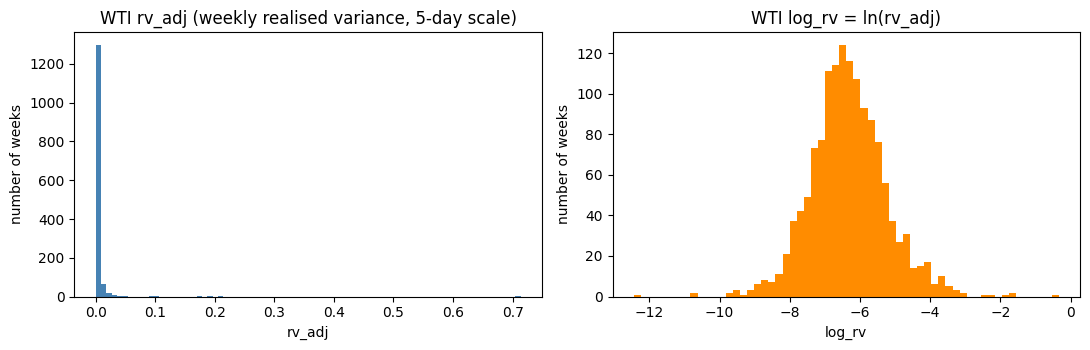

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(panel["wti_rv_adj"].dropna(), bins=80, color="steelblue")
axes[0].set_title("WTI rv_adj (weekly realised variance, 5-day scale)")
axes[0].set_xlabel("rv_adj")
axes[1].hist(panel["wti_log_rv"].dropna(), bins=60, color="darkorange")
axes[1].set_title("WTI log_rv = ln(rv_adj)")
axes[1].set_xlabel("log_rv")
for ax in axes:
    ax.set_ylabel("number of weeks")
fig.tight_layout()
plt.show()

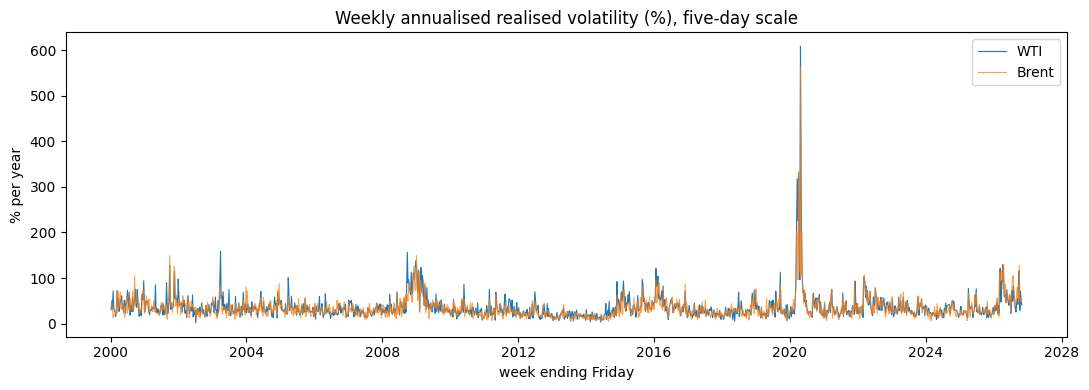

In [32]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(panel.index, panel["wti_rvol_ann"], linewidth=0.8, label="WTI")
ax.plot(panel.index, panel["brent_rvol_ann"], linewidth=0.8, label="Brent", alpha=0.75)
ax.set_title("Weekly annualised realised volatility (%), five-day scale")
ax.set_ylabel("% per year")
ax.set_xlabel("week ending Friday")
ax.legend()
fig.tight_layout()
plt.show()

## G. Save the processed files

Both files are derived from the third-party daily prices, so they are **not committed**
(`data/processed/*.csv` is in `.gitignore`). Running notebooks 01 and 02 regenerates them.

In [33]:
DAILY_RETURNS_PATH.parent.mkdir(parents=True, exist_ok=True)
returns.to_csv(DAILY_RETURNS_PATH, date_format="%Y-%m-%d")
panel.to_csv(WEEKLY_PANEL_PATH, date_format="%Y-%m-%d")

for path in (DAILY_RETURNS_PATH, WEEKLY_PANEL_PATH):
    print(f"{path.relative_to(ROOT)}: {path.stat().st_size / 1024:,.0f} KB")

# Read back and confirm the panel is unchanged on disk
check = pd.read_csv(WEEKLY_PANEL_PATH, parse_dates=["date", "eia_week"], index_col="date")
assert check.shape == panel.shape
assert check.index.equals(panel.index)
print("\nread back:", check.shape, "- identical index")

data/processed/daily_returns.csv: 610 KB
data/processed/weekly_panel.csv: 478 KB

read back: (1400, 27) - identical index


## What to remember from stage 2

**Decisions to describe in the paper**

1. **The timing rule.** For panel week `t`, the target is the volatility of week `t+1`;
   only prices up to Friday `t` and EIA data published by Friday `t` (the week ending
   `t - 7`) are used. The EIA report released *during* the target week is never used. This
   is what the `eia_week` column and the 7-day lag assertion enforce, and it is the single
   most important thing to state in the Methodology section.
2. **The negative WTI price, and the bridged return.** WTI settled at -36.98 USD on
   2020-04-20, so `ln(P)` does not exist. The observation is skipped and a single return
   `ln(8.91 / 18.31) = -0.720` is measured from 2020-04-17 to 2020-04-21, dated on the
   later day and recorded as covering 2 trading days. The week ending 2020-04-24 therefore
   covers all 5 trading days and becomes the most volatile week of the sample
   (609% annualised).
   *This week's variance is a lower bound.* A single return from 18.31 to 8.91 measures the
   net move over two days, while the price actually fell to -36.98 and came back: the true
   two-day variation was far larger than the bridge can show. Brent, which never went
   negative, is the robustness check for the episode, and
   `wti_negative_price_week` flags the week so it can be excluded from a robustness run.
   The flag is never a model input.
2. **Release-date lag.** EIA data are dated the Friday the week ended but published the
   following Wednesday (Thursday after a holiday). Using `release_date = Friday + 6 days`
   with a backward `merge_asof`, every panel week uses the EIA week ending 7 days earlier.
   All 1 400 rows have exactly this 7-day lag, so no forecast can use an unpublished number.
4. **Short weeks: the `n_days` rule and the five-day adjustment.** `n_days` counts the
   trading days a week's returns cover. US holidays leave about 220 four-day weeks for WTI
   and 147 for Brent out of 1 400. Because realised variance is a sum, those weeks would be
   mechanically smaller, so the panel uses `rv_adj = rv * 5 / n_days` and models
   `log_rv = ln(rv_adj)`. Weeks covering fewer than 3 days are dropped: that is now
   **0 weeks for WTI and 1 for Brent** (the Christmas week ending 2018-12-28), against 53
   and 43 before the price gaps were fixed.
5. **The daily price gaps, and why the API is used.** EIA's published daily `.xls` price
   files silently omit ordinary trading days — 757 for WTI and 900 for Brent, worst in 1999
   (86 days), 2003 (111) and 2011 (40). The prices come from the EIA API v2 instead, which
   returns the complete series; on the 9 529 dates both sources cover, every WTI price is
   identical. The API itself is missing 8 days that the `.xls` has, and those are filled
   back from the `.xls`, so neither source's gaps survive. Brent prices disagree on 3 dates
   out of 10 000 (at most 1.13 USD); the API value is kept and the disagreement is reported
   by notebook 01.
6. **The proxy and how forecasts will be scored.** Weekly realised variance follows
   Andersen et al. (2003) — a sum of squared daily log returns, modelled in logs — built
   from daily returns as in French, Schwert & Stambaugh (1987). With about 5 returns a
   week it is conditionally unbiased but noisy, so every model's R-squared has a ceiling
   that comes from the measurement rather than the model. Models are therefore fitted on
   `log_rv` but **scored on the variance scale**, with QLIKE as the main loss plus MSE and
   the GLS Mincer-Zarnowitz regression (Patton, 2011; Patton & Sheppard, 2009); MSE on
   `log_rv` is not used, because it does not rank forecasts reliably under a noisy proxy.
   Forecasts are converted back with `exp(mu + s2/2)`, without which they are biased low.
6. **Cushing stocks start on 2004-04-09**, so they enter the panel on 2004-04-16 after the
   release lag. The series is kept with `NaN` before that date rather than dropped, and no
   row is removed. Stage 3 has to decide between starting the sample in 2004 and leaving
   this one series out — Cushing is the WTI delivery point, so it is worth the shorter
   sample.

**What the checks found**

The proxy's assumptions hold. The mean daily return is under 1% of its standard deviation
for both series, so not subtracting a mean costs nothing; lag-1 autocorrelation is inside
its 95% band for Brent everywhere and for WTI in the train and tune periods, and the
whole-sample and test-period readings only fall outside it because of March-April 2020 —
excluding those two months the test-period figure is -0.001. The FSS correction is
therefore reported as a robustness proxy and not used as the target: at weekly frequency
it is non-positive in about 8% of weeks and would cut the week ending 2020-04-24 from
0.714 to 0.196.

Two facts about the target to keep in mind. The week ending 2020-04-24 is the highest
`log_rv` of the sample for both benchmarks, and it stands 1.22 log points above the next
week for WTI (a variance 3.4 times larger) and 1.05 for Brent (2.9 times) — modelling the
log rather than the level is what keeps that single week from dominating the loss. And the
EIA data have no holes inside the panel: no EIA column has a missing value after its first
observation, the only gaps in the raw CSVs being six weeks in 1982-83 and one in 1991,
when EIA published less often, all far before the 2000 sample start.

**What is left to watch**

The early-sample bias that stage 2 previously carried is gone: with the API prices, every
year from 2000 averages about 4.8 trading days per week, and no WTI week loses its
variance. What remains is ordinary and handled: US holiday weeks (corrected by `rv_adj`),
the single short Brent week, and Cushing's late start.

**Next:** `03_features.ipynb` builds the forecast target and the features (inventory
surprises, PCA, regimes).